In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
threshold = 0.7

In [ ]:
lagged_df = pd.read_csv('new_runs/RF/run_with_lagged_and_lai/performance.csv')

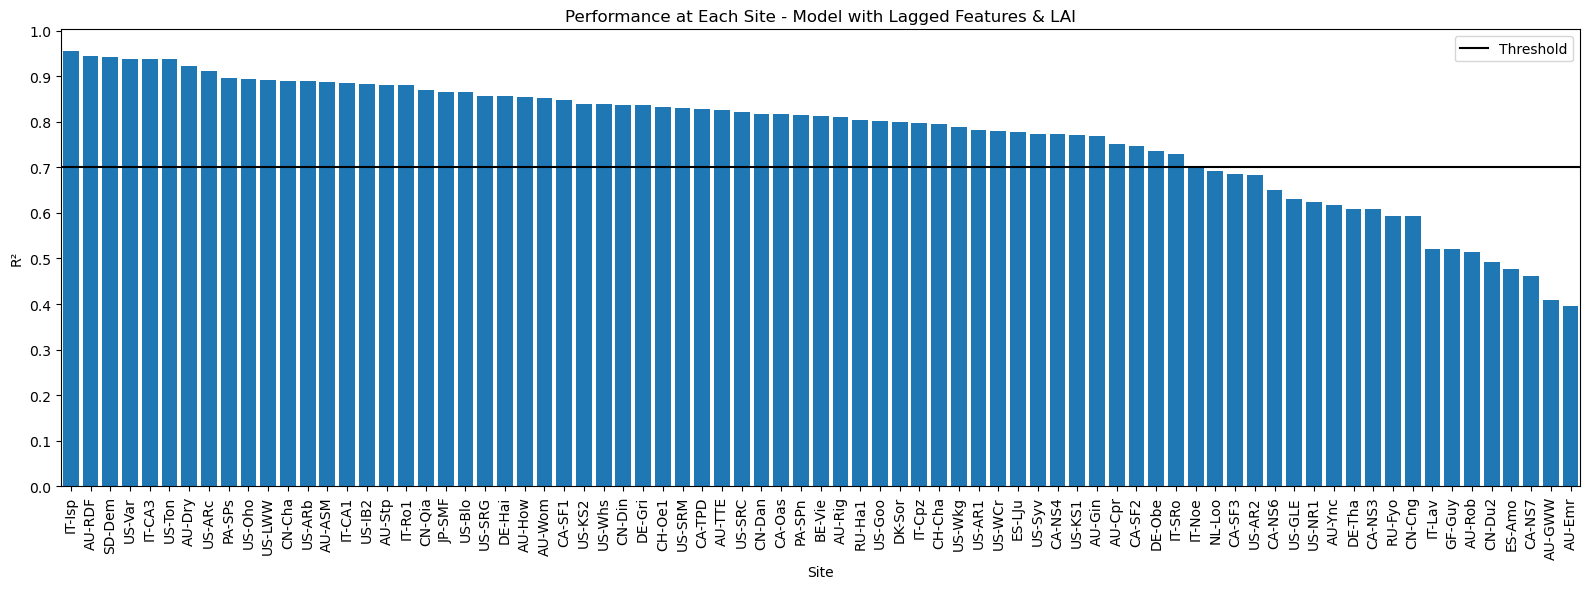

In [ ]:
#2
sorted_lagged_df = lagged_df.sort_values(by="test_score", ascending=False)

plt.figure(figsize=(16, 6))
plt.bar(sorted_lagged_df["SITE_ID"], sorted_lagged_df["test_score"])
plt.axhline(threshold, color='black', linestyle='-', label='Threshold')
plt.legend()
plt.xticks(rotation=90)
plt.ylabel("R²")
plt.xlabel("Site")
plt.title("Performance at Each Site - Model with Lagged Features & LAI")
plt.tight_layout()
plt.margins(x=0.001)
plt.yticks(np.arange(0, 1.01, 0.1))
plt.savefig('graphs/Two_performance_model1.png', dpi=1200)
plt.show()

In [22]:
above_thresh_lagged = (lagged_df["test_score"] >= threshold).sum()
performantSites_lagged_df = lagged_df[(lagged_df["test_score"] >= threshold)]
print(above_thresh_lagged)

58


In [23]:
poorPrfSites = lagged_df[(lagged_df["test_score"] < threshold)]["SITE_ID"].values

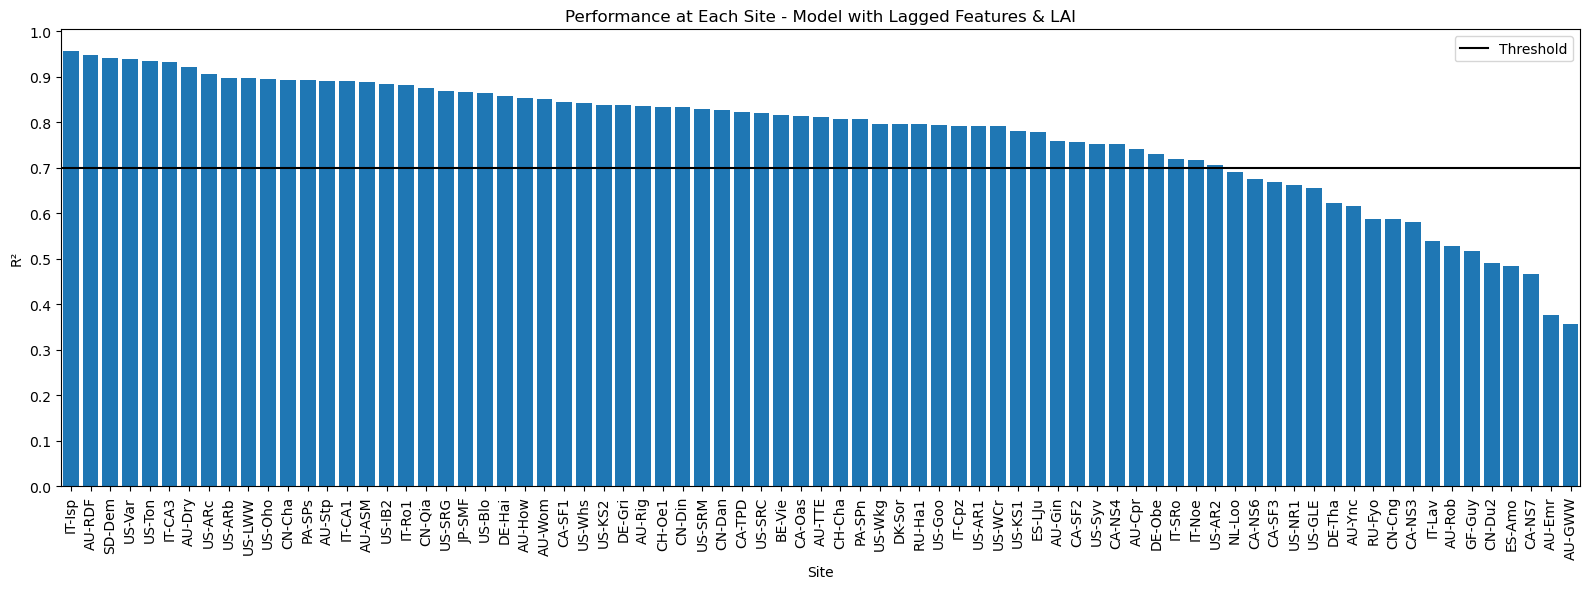

In [ ]:
lagged2_df = pd.read_csv('/new_runs/RF/run_with_lagged_and_lai02/performance.csv')
#2
sorted_lagged2_df = lagged2_df.sort_values(by="test_score", ascending=False)

plt.figure(figsize=(16, 6))
plt.bar(sorted_lagged2_df["SITE_ID"], sorted_lagged2_df["test_score"])
plt.axhline(threshold, color='black', linestyle='-', label='Threshold')
plt.legend()
plt.xticks(rotation=90)
plt.ylabel("R²")
plt.xlabel("Site")
plt.title("Performance at Each Site - Model with Lagged Features & LAI")
plt.tight_layout()
plt.margins(x=0.001)
plt.yticks(np.arange(0, 1.01, 0.1))
plt.show()

In [25]:
above_thresh_laggedLai2 = (sorted_lagged2_df["test_score"] >= threshold).sum()
poorPrfSites2 = sorted_lagged2_df[(sorted_lagged2_df["test_score"] < threshold)]["SITE_ID"].values
print(above_thresh_laggedLai2)

59


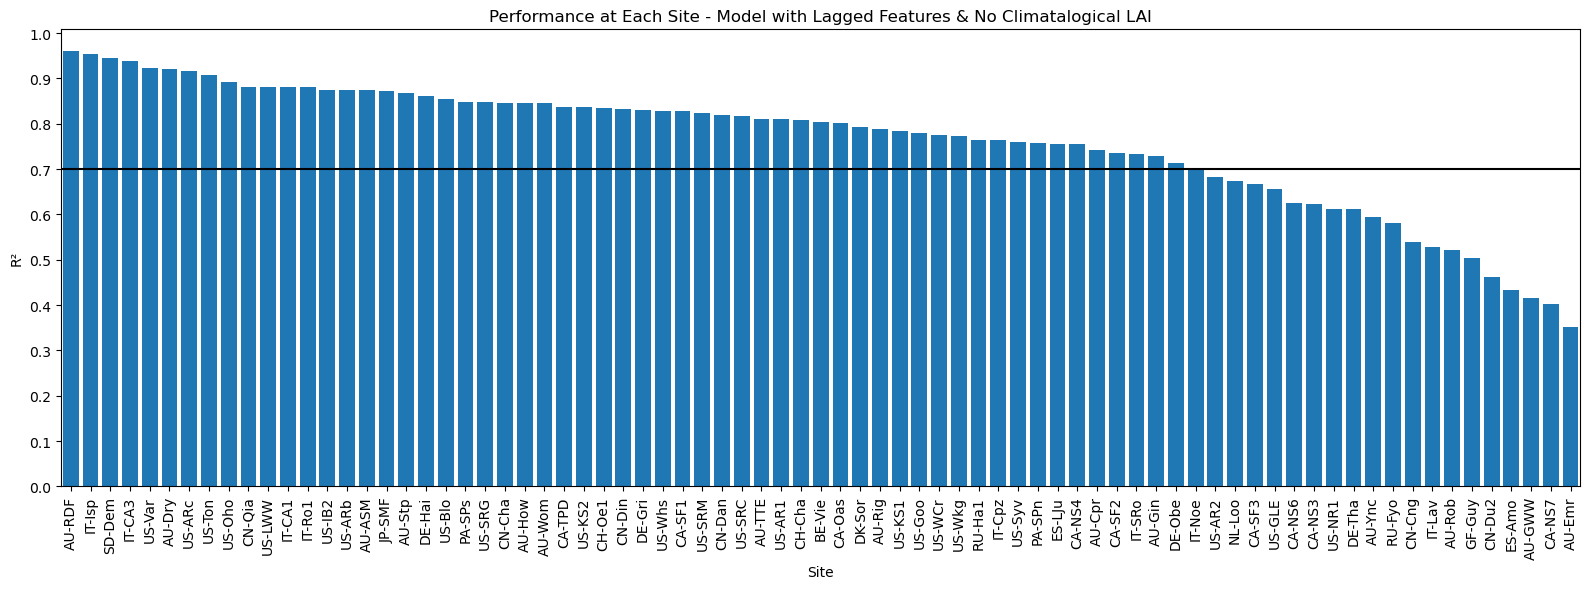

In [ ]:
#2
lagged_noLai_df = pd.read_csv('new_runs/RF/run_with_lagged01/performance.csv')
sorted_lagged_noLai_df = lagged_noLai_df.sort_values(by="test_score", ascending=False)

plt.figure(figsize=(16, 6))
plt.bar(sorted_lagged_noLai_df["SITE_ID"], sorted_lagged_noLai_df["test_score"])
plt.axhline(threshold, color='black')
plt.xticks(rotation=90)
plt.ylabel("R²")
plt.xlabel("Site")
plt.title("Performance at Each Site - Model with Lagged Features & No Climatalogical LAI")
plt.yticks(np.arange(0, 1.01, 0.1))
plt.tight_layout()
plt.margins(x=0.001)
plt.show()

In [27]:
above_thresh_lagged_noLai = (sorted_lagged_noLai_df["test_score"] >= threshold).sum()
print(above_thresh_lagged_noLai)

57


In [ ]:
no_lagged_df = pd.read_csv('new_runs/RF/run_without_lagged01/performance.csv')

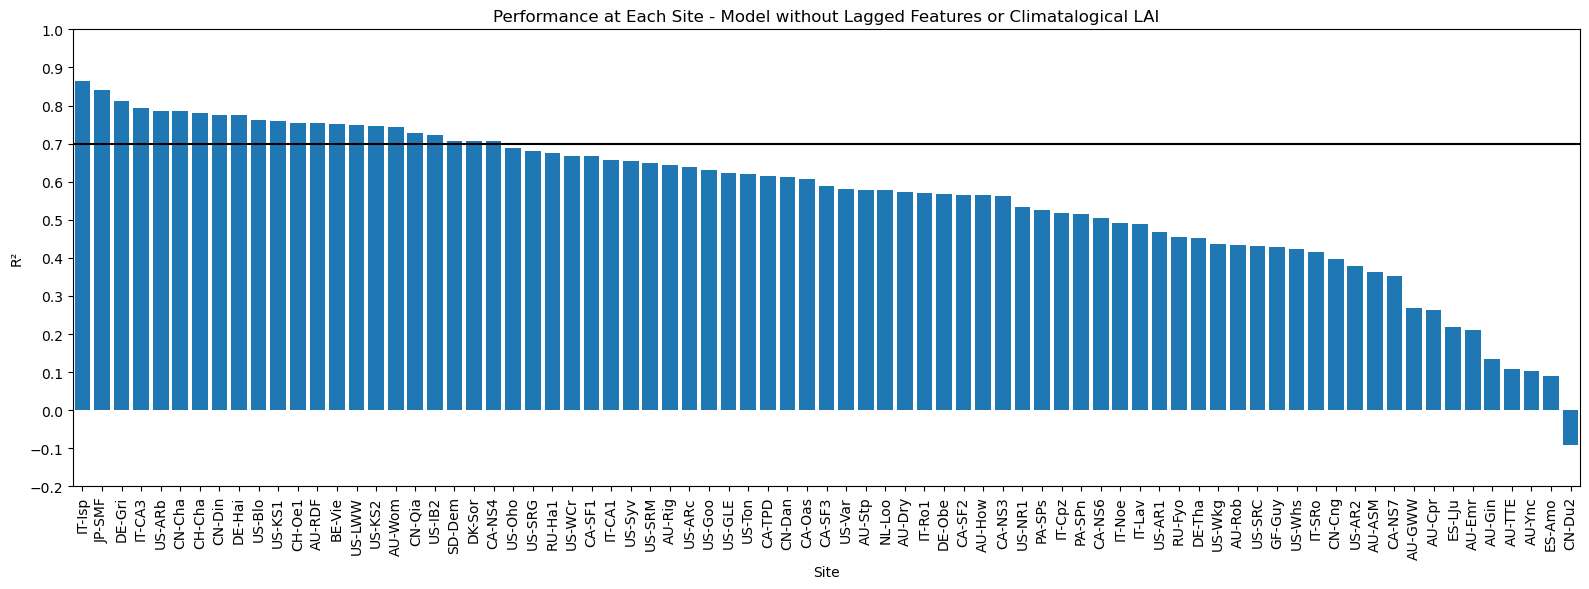

In [29]:
#2
sorted_df = no_lagged_df.sort_values(by="test_score", ascending=False)

plt.figure(figsize=(16, 6))
plt.bar(sorted_df["SITE_ID"], sorted_df["test_score"])
plt.axhline(threshold, color='black')
plt.xticks(rotation=90)
plt.ylabel("R²")
plt.xlabel("Site")
plt.title("Performance at Each Site - Model without Lagged Features or Climatalogical LAI")
plt.yticks(np.arange(-0.2, 1.01, 0.1))
plt.tight_layout()
plt.margins(x=0.001)
plt.show()

In [30]:
above_thresh = (no_lagged_df["test_score"] >= threshold).sum()
performantSites_no_lagged_df = no_lagged_df[(no_lagged_df["test_score"] >= threshold)]
print(above_thresh)

22


In [ ]:
eventdf = pd.read_csv("new_runs/RF/run_with_lagged_and_lai/event.csv")
testdf = pd.read_csv("new_runs/RF/run_with_lagged_and_lai/test.csv")
eventdf = eventdf[~eventdf["SITE_ID"].isin(poorPrfSites)]
testdf = testdf[~testdf["SITE_ID"].isin(poorPrfSites)]

In [27]:
def dfToList(df, sites):
    data = []
    for s in sites:
        vals = df.loc[df["SITE_ID"] == s, "actual - predicted"].values
        data.append(vals)
    return data

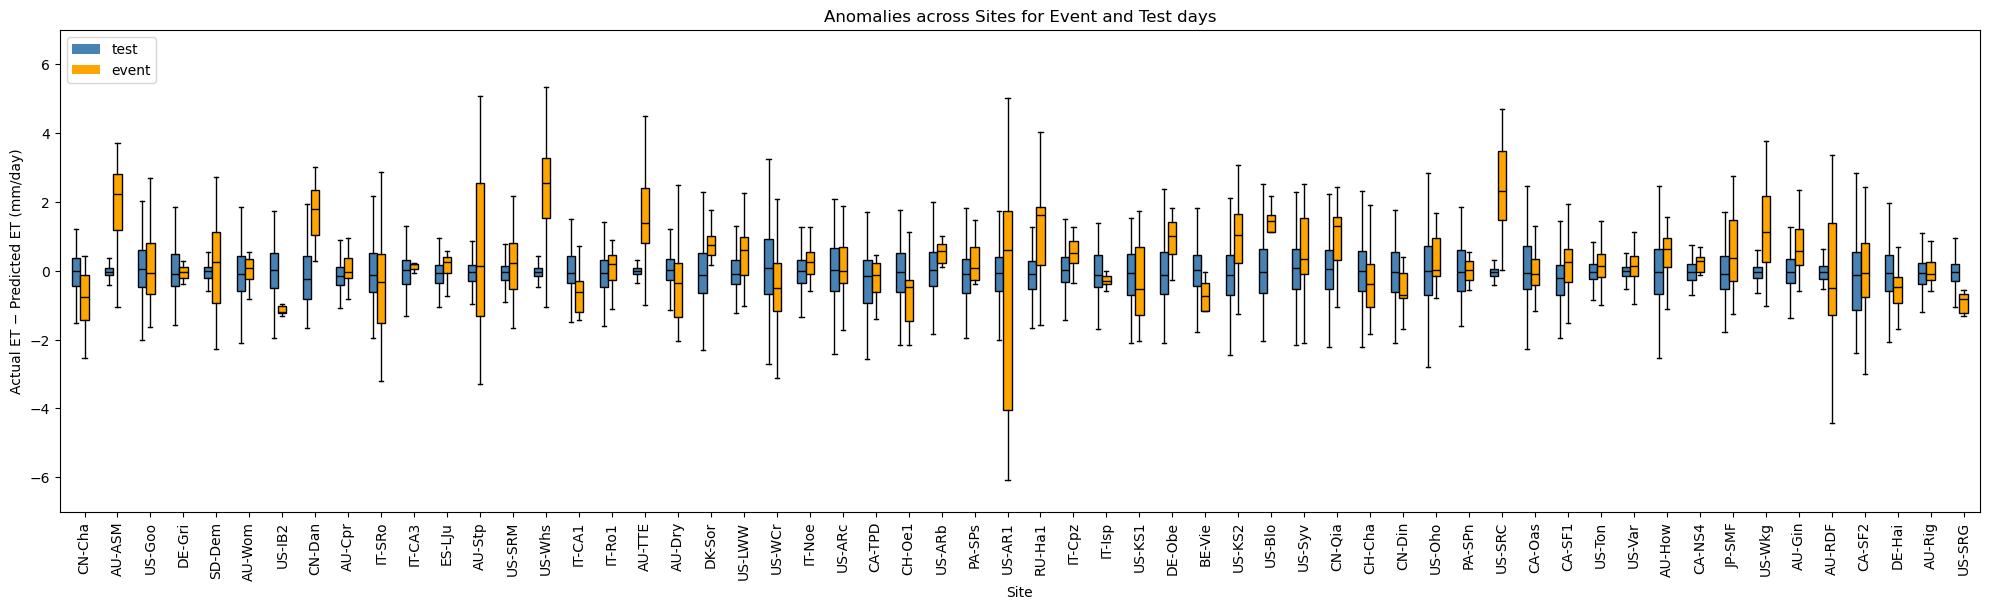

In [47]:
#5
sites = eventdf["SITE_ID"].unique()
x = np.arange(len(sites))


event_data = dfToList(eventdf, sites)
test_data = dfToList(testdf, sites)

fig, ax = plt.subplots(figsize=(20, 6))
w = 0.25
ax.boxplot( test_data, positions=x - w, widths=w, patch_artist=True, showfliers=False, boxprops=dict(facecolor="steelblue"), medianprops=dict(color="black", linewidth=1))
ax.boxplot( event_data, positions=x, widths=w, patch_artist=True, showfliers=False, boxprops=dict(facecolor="orange"), medianprops=dict(color="black", linewidth=1))
ax.set_xticks(x)
ax.set_xticklabels(sites, rotation=90)
ax.set_ylabel("Actual ET − Predicted ET (mm/day)")
ax.set_xlabel("Site")
ax.set_ylim(-7, 7)
plt.legend(handles=[Patch(facecolor="steelblue", label="test"), Patch(facecolor="orange", label="event")], loc="upper left")
plt.tight_layout()
plt.title("Anomalies across Sites for Event and Test days")
plt.show()

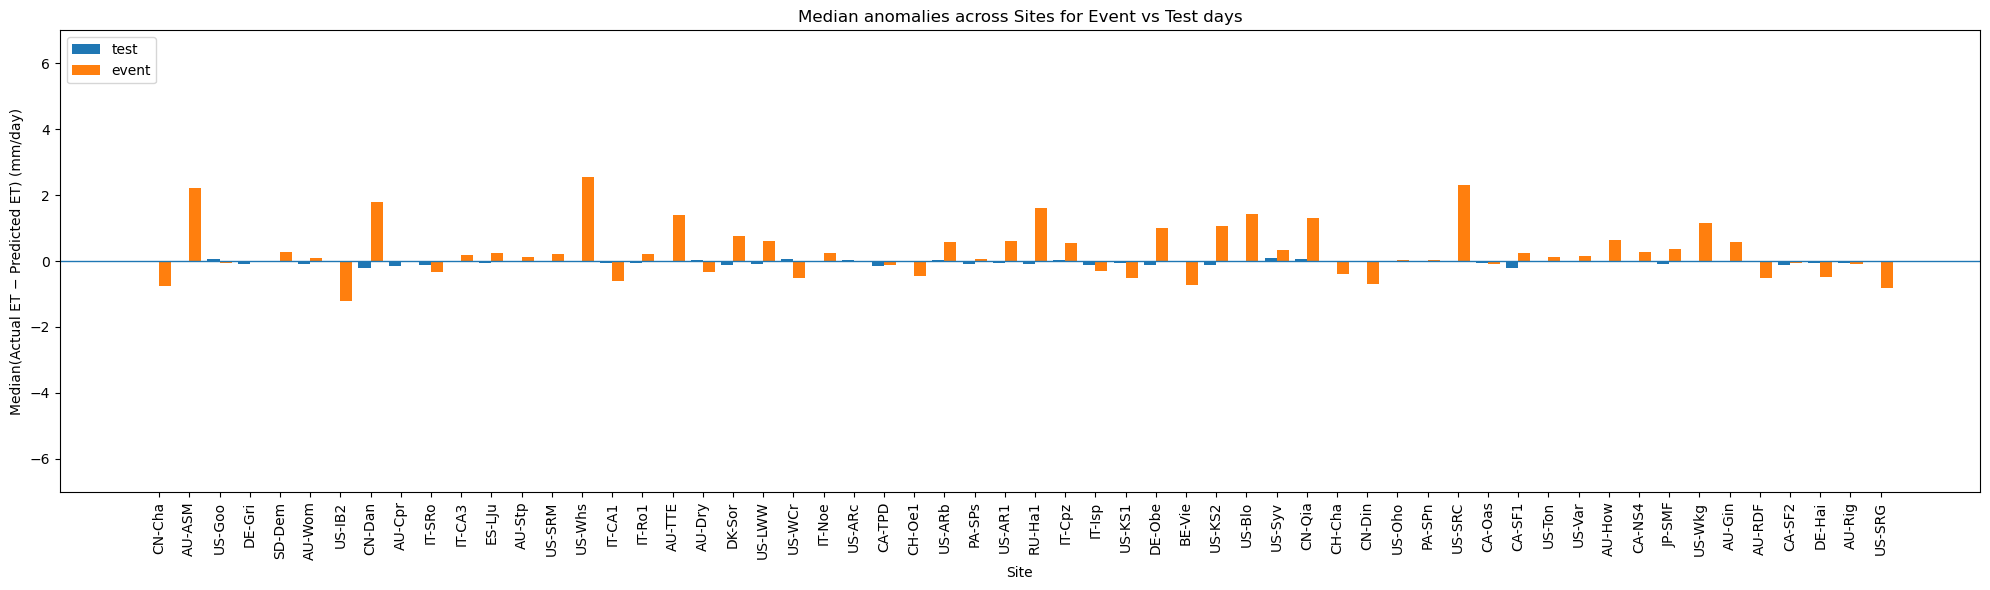

In [107]:
import numpy as np
import matplotlib.pyplot as plt

sites = eventdf["SITE_ID"].unique()
x = np.arange(len(sites))
w = 0.4  # bar width

event_data = dfToList(eventdf, sites)  # list of arrays/lists, one per site
test_data  = dfToList(testdf, sites)

# pick what you want bars to represent:
event_med = np.array([np.median(vals) if len(vals) else np.nan for vals in event_data])
test_med  = np.array([np.median(vals) if len(vals) else np.nan for vals in test_data])

# optional: error bars (IQR)
event_q1 = np.array([np.percentile(vals, 25) if len(vals) else np.nan for vals in event_data])
event_q3 = np.array([np.percentile(vals, 75) if len(vals) else np.nan for vals in event_data])
test_q1  = np.array([np.percentile(vals, 25) if len(vals) else np.nan for vals in test_data])
test_q3  = np.array([np.percentile(vals, 75) if len(vals) else np.nan for vals in test_data])

event_err = np.vstack([event_med - event_q1, event_q3 - event_med])  # asymmetric
test_err  = np.vstack([test_med - test_q1,  test_q3 - test_med])

fig, ax = plt.subplots(figsize=(20, 6))

ax.bar(x - w/2, test_med, width=w, label="test")
ax.bar(x + w/2, event_med, width=w, label="event")

# if you want IQR as error bars, uncomment:
# ax.errorbar(x - w/2, test_med, yerr=test_err, fmt='none', capsize=2)
# ax.errorbar(x + w/2, event_med, yerr=event_err, fmt='none', capsize=2)

ax.axhline(0, linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(sites, rotation=90)
ax.set_ylabel("Median(Actual ET − Predicted ET) (mm/day)")
ax.set_xlabel("Site")
ax.set_ylim(-7, 7)
ax.set_title("Median anomalies across Sites for Event vs Test days")
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


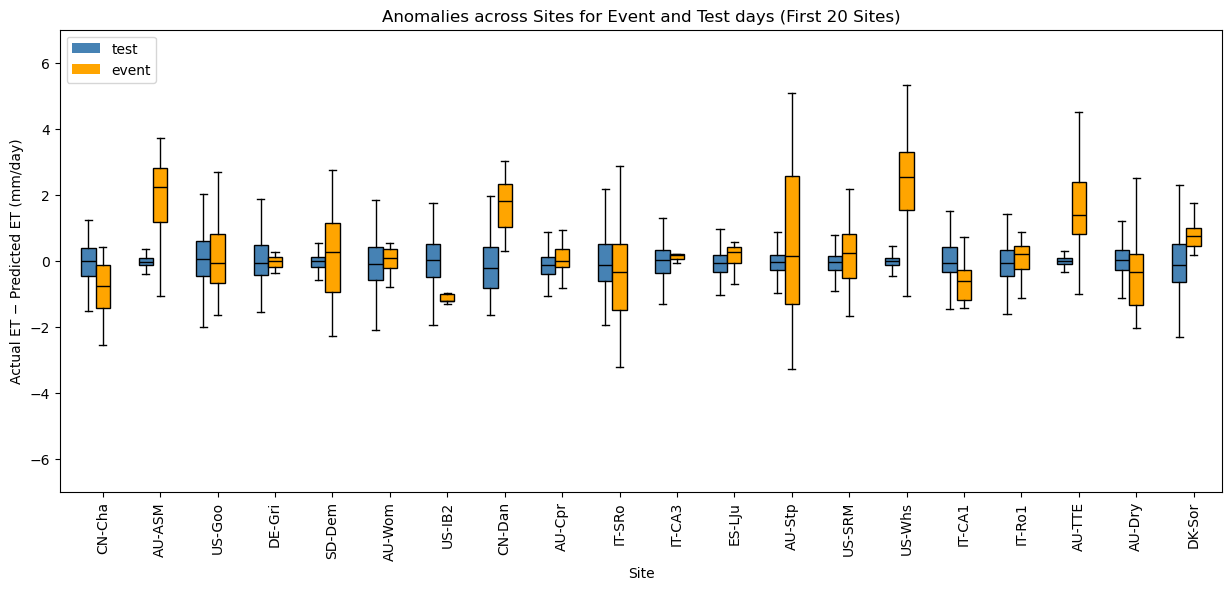

In [49]:
#4
sites = eventdf["SITE_ID"].unique()[:20]
x = np.arange(len(sites))


event_data = dfToList(eventdf, sites)
test_data = dfToList(testdf, sites)

fig, ax = plt.subplots(figsize=(15, 6))
w = 0.25
ax.boxplot( test_data, positions=x - w, widths=w, patch_artist=True, showfliers=False, boxprops=dict(facecolor="steelblue"), medianprops=dict(color="black", linewidth=1))
ax.boxplot( event_data, positions=x, widths=w, patch_artist=True, showfliers=False, boxprops=dict(facecolor="orange"), medianprops=dict(color="black", linewidth=1))
ax.set_xticks(x)
ax.set_xticklabels(sites, rotation=90)
ax.set_ylabel("Actual ET − Predicted ET (mm/day)")
ax.set_xlabel("Site")
ax.set_ylim(-7, 7)
plt.legend(handles=[Patch(facecolor="steelblue", label="test"), Patch(facecolor="orange", label="event")], loc="upper left")
plt.title("Anomalies across Sites for Event and Test days (First 20 Sites)")
plt.show()

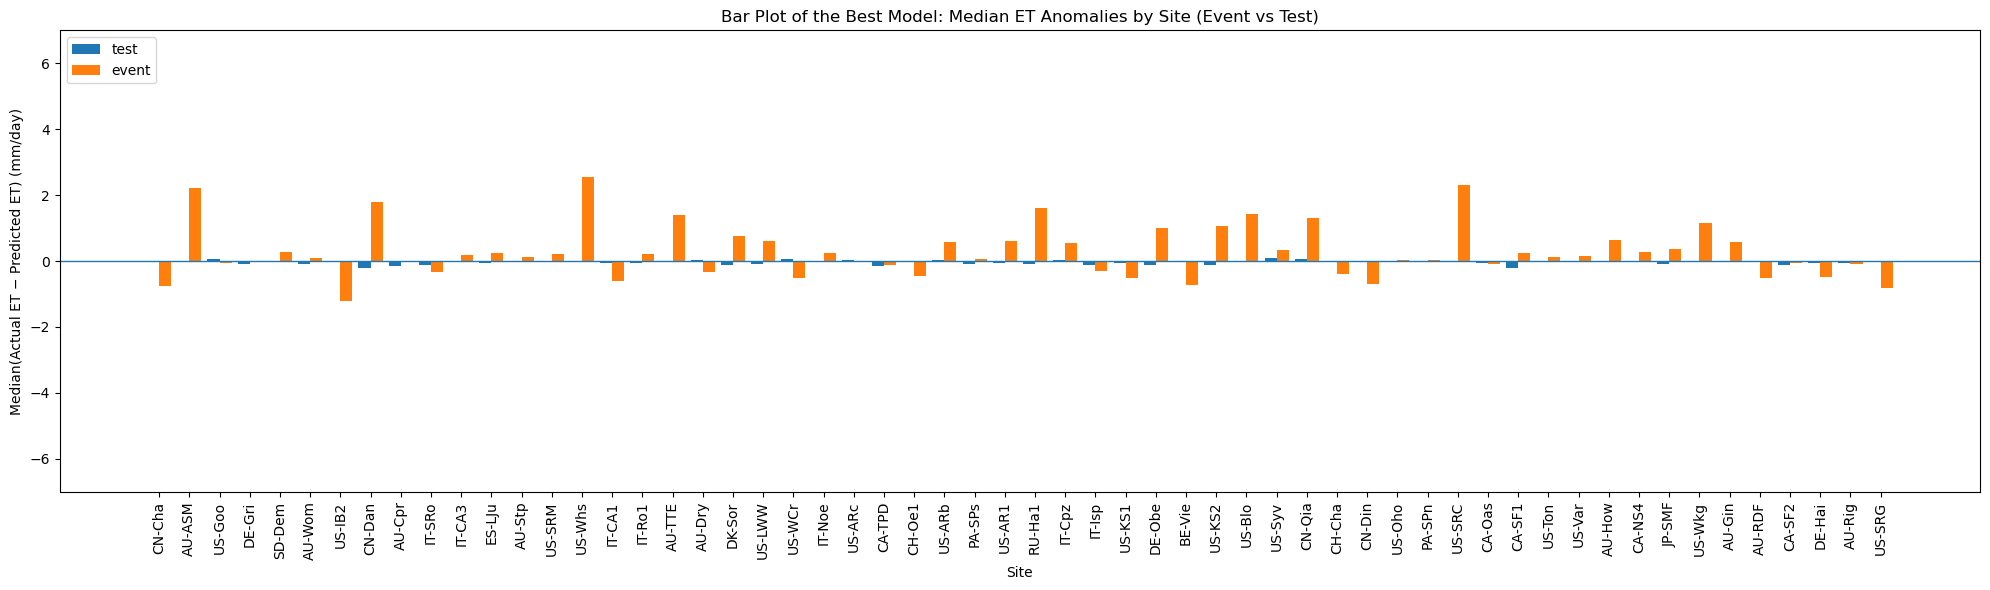

In [109]:
import numpy as np
import matplotlib.pyplot as plt

sites = eventdf["SITE_ID"].unique()
x = np.arange(len(sites))
w = 0.4  # bar width

event_data = dfToList(eventdf, sites)  # list: one list/array per site
test_data  = dfToList(testdf, sites)

# bars = median anomaly per site (robust to outliers)
event_med = np.array([np.median(v) if len(v) else np.nan for v in event_data])
test_med  = np.array([np.median(v) if len(v) else np.nan for v in test_data])

fig, ax = plt.subplots(figsize=(20, 6))
ax.bar(x - w/2, test_med,  width=w, label="test")
ax.bar(x + w/2, event_med, width=w, label="event")

ax.axhline(0, linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(sites, rotation=90)
ax.set_ylabel("Median(Actual ET − Predicted ET) (mm/day)")
ax.set_xlabel("Site")
ax.set_ylim(-7, 7)
ax.set_title("Bar Plot of the Best Model: Median ET Anomalies by Site (Event vs Test)")
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


In [51]:
#test is basically all normal days, and event is all the days flagged as extreme wet events, and since there is a difference between these two, that means ET depends on soil water content during extreme events

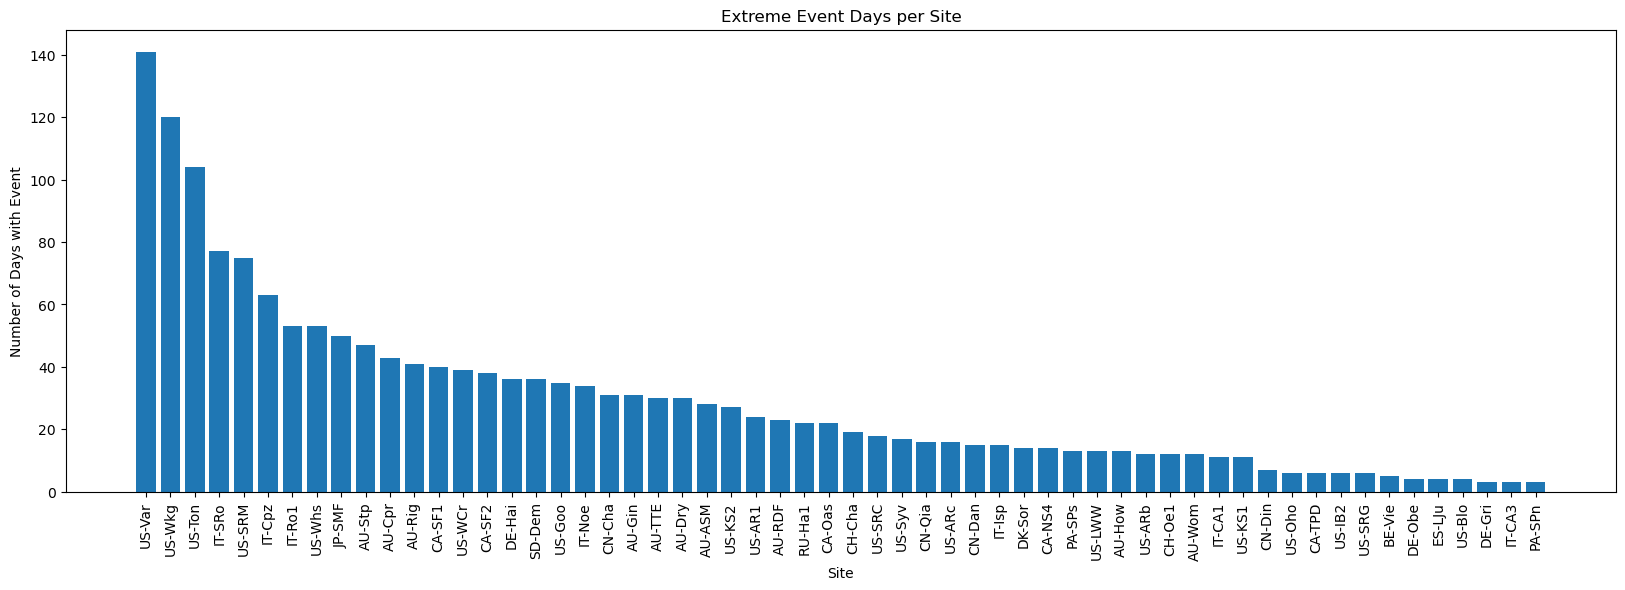

In [ ]:
#1
import matplotlib.pyplot as plt

extremePlotDf = eventdf[["SITE_ID", "day"]]

extreme_event_days = (extremePlotDf.drop_duplicates().groupby("SITE_ID").size().sort_values(ascending=False))
plt.figure(figsize=(20, 6))
plt.bar(extreme_event_days.index, extreme_event_days.values)
plt.xticks(rotation=90)
plt.ylabel("Number of Days with Event")
plt.xlabel("Site")
plt.title("Extreme Event Days per Site")
#plt.savefig('graphs/One_numEvents.png', dpi=1200)
plt.show()

In [115]:
print(extreme_event_days.sum())

1691


In [105]:
 print(extreme_event_days)

SITE_ID
US-Var    141
US-Wkg    120
US-Ton    104
IT-SRo     77
US-SRM     75
IT-Cpz     63
IT-Ro1     53
US-Whs     53
JP-SMF     50
AU-Stp     47
AU-Cpr     43
AU-Rig     41
CA-SF1     40
US-WCr     39
CA-SF2     38
DE-Hai     36
SD-Dem     36
US-Goo     35
IT-Noe     34
CN-Cha     31
AU-Gin     31
AU-TTE     30
AU-Dry     30
AU-ASM     28
US-KS2     27
US-AR1     24
AU-RDF     23
RU-Ha1     22
CA-Oas     22
CH-Cha     19
US-SRC     18
US-Syv     17
CN-Qia     16
US-ARc     16
CN-Dan     15
IT-Isp     15
DK-Sor     14
CA-NS4     14
PA-SPs     13
US-LWW     13
AU-How     13
US-ARb     12
CH-Oe1     12
AU-Wom     12
IT-CA1     11
US-KS1     11
CN-Din      7
US-Oho      6
CA-TPD      6
US-IB2      6
US-SRG      6
BE-Vie      5
DE-Obe      4
ES-LJu      4
US-Blo      4
DE-Gri      3
IT-CA3      3
PA-SPn      3
dtype: int64


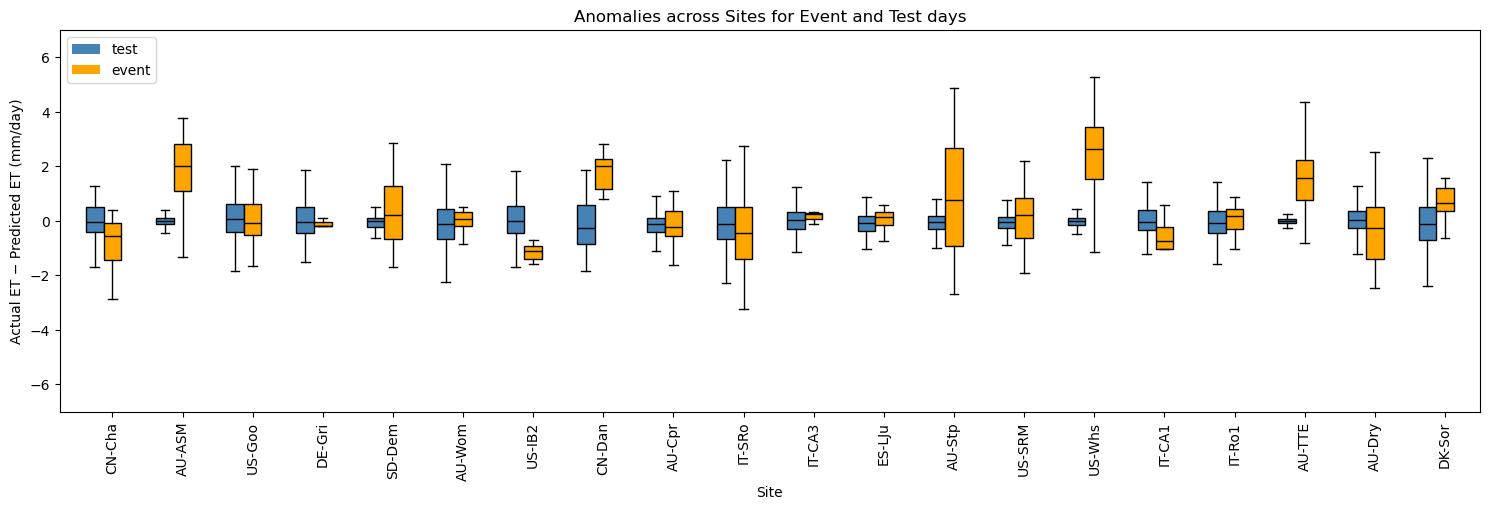

In [ ]:
event2df = pd.read_csv("new_runs/RF/run_with_lagged_and_lai02/event.csv")
test2df = pd.read_csv("new_runs/RF/run_with_lagged_and_lai02/test.csv")
event2df = event2df[~event2df["SITE_ID"].isin(poorPrfSites2)]
test2df = test2df[~test2df["SITE_ID"].isin(poorPrfSites2)]

sites2 = event2df["SITE_ID"].unique()[:20]
x = np.arange(len(sites2))


event_data2 = dfToList(event2df, sites2)
test_data2 = dfToList(test2df, sites2)

fig, ax = plt.subplots(figsize=(15, 5))
w = 0.25
ax.boxplot( test_data2, positions=x - w, widths=w, patch_artist=True, showfliers=False, boxprops=dict(facecolor="steelblue"), medianprops=dict(color="black", linewidth=1))
ax.boxplot( event_data2, positions=x, widths=w, patch_artist=True, showfliers=False, boxprops=dict(facecolor="orange"), medianprops=dict(color="black", linewidth=1))
ax.set_xticks(x)
ax.set_xticklabels(sites2, rotation=90)
ax.set_ylabel("Actual ET − Predicted ET (mm/day)")
ax.set_xlabel("Site")
ax.set_ylim(-7, 7)
plt.legend(handles=[Patch(facecolor="steelblue", label="test"), Patch(facecolor="orange", label="event")], loc="upper left")
plt.tight_layout()
plt.title("Anomalies across Sites for Event and Test days")
plt.show()

Selected site: AU-Wom


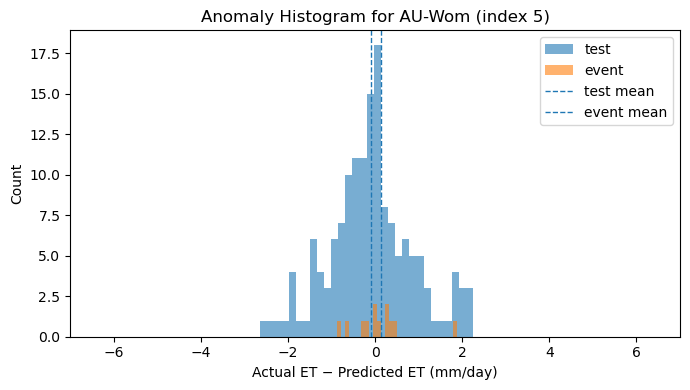

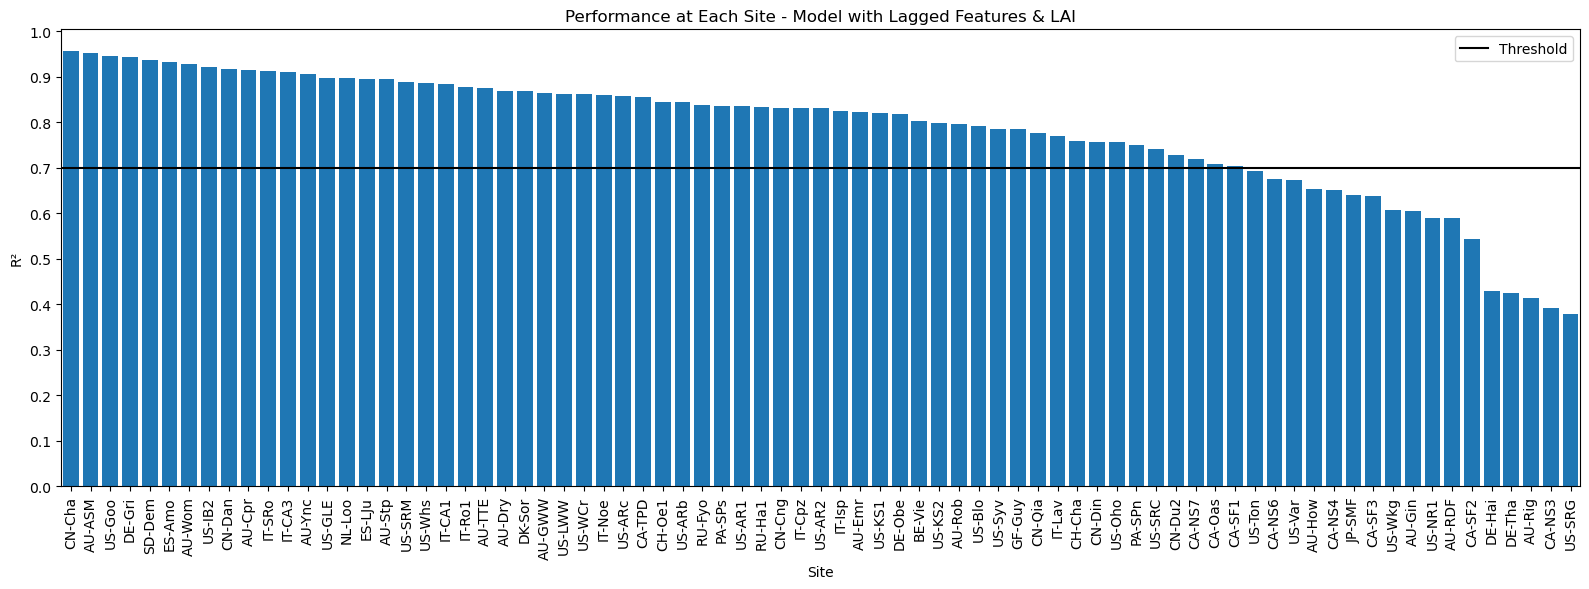

In [ ]:
lagged4_df = pd.read_csv('new_runs/RF/run_with_lagged_et01/performance.csv')
#2
sorted_lagged4_df = lagged4_df.sort_values(by="test_score", ascending=False)

plt.figure(figsize=(16, 6))
plt.bar(lagged4_df["SITE_ID"], sorted_lagged4_df["test_score"])
plt.axhline(threshold, color='black', linestyle='-', label='Threshold')
plt.legend()
plt.xticks(rotation=90)
plt.ylabel("R²")
plt.xlabel("Site")
plt.title("Performance at Each Site - Model with Lagged Features & LAI")
plt.tight_layout()
plt.margins(x=0.001)
plt.yticks(np.arange(0, 1.01, 0.1))
plt.show()

In [15]:
above_thresh_lagged = (lagged4_df["test_score"] >= threshold).sum()
performantSites_lagged_df = lagged4_df[(lagged4_df["test_score"] >= threshold)]
print(above_thresh_lagged)
poorPrfSites = lagged4_df[(lagged4_df["test_score"] < threshold)]["SITE_ID"].values

poorPrfSites_df = lagged4_df[lagged4_df["test_score"] < threshold][
    ["SITE_ID", "test_score"]
]

poorPrfSites_df.to_csv(
    "poor_performance_sites.csv",
    index=False
)

60


In [ ]:
eventdf = pd.read_csv("new_runs/RF/run_with_lagged_et01/event.csv")
testdf = pd.read_csv("new_runs/RF/run_with_lagged_et01/test.csv")
eventdf = eventdf[~eventdf["SITE_ID"].isin(poorPrfSites)]
testdf = testdf[~testdf["SITE_ID"].isin(poorPrfSites)]

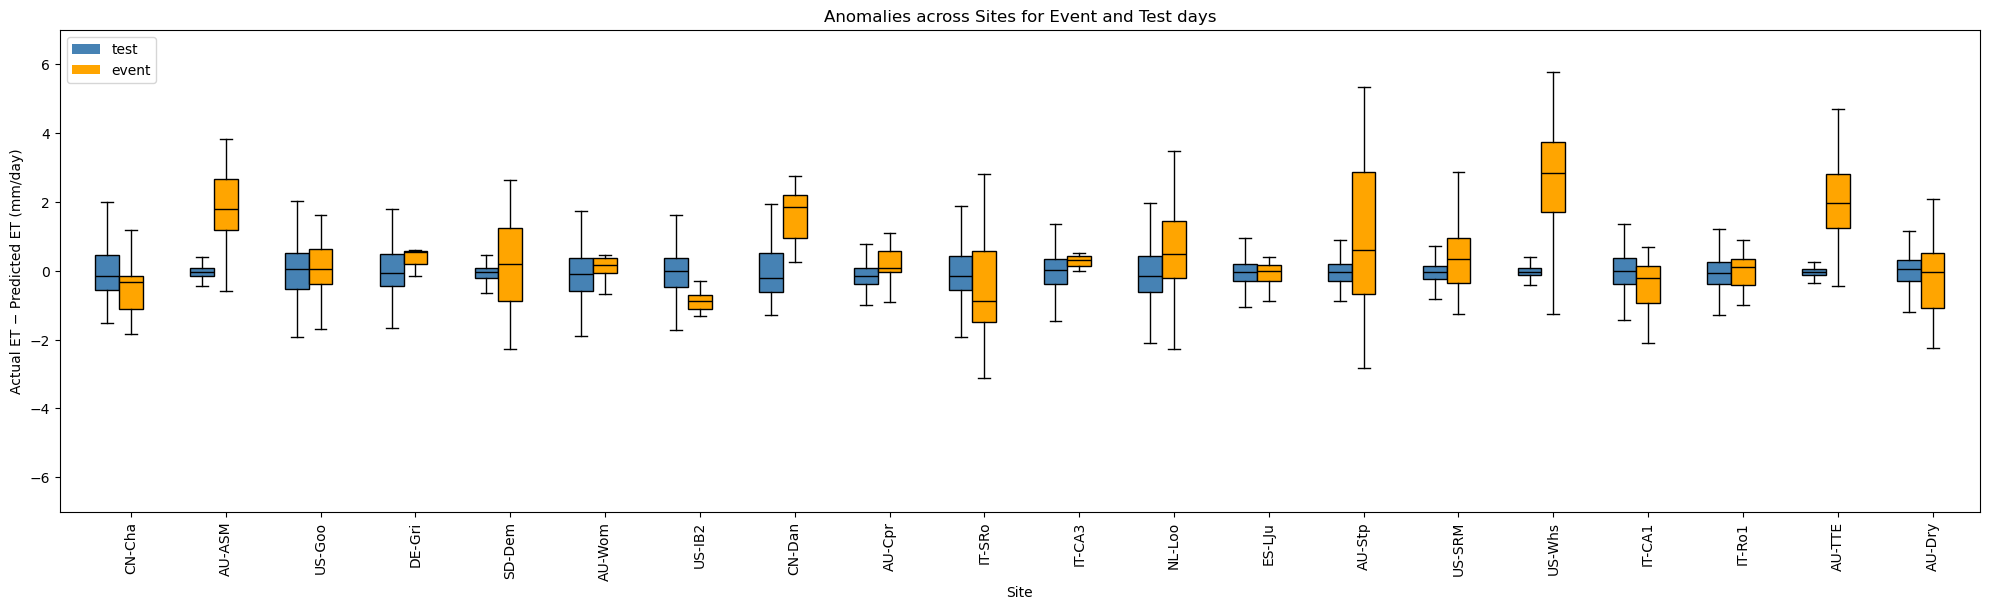

In [69]:
#5
sites = eventdf["SITE_ID"].unique()[:20]
x = np.arange(len(sites))

event_data = dfToList(eventdf, sites)
test_data = dfToList(testdf, sites)

fig, ax = plt.subplots(figsize=(20, 6))
w = 0.25
ax.boxplot( test_data, positions=x - w, widths=w, patch_artist=True, showfliers=False, boxprops=dict(facecolor="steelblue"), medianprops=dict(color="black", linewidth=1))
ax.boxplot( event_data, positions=x, widths=w, patch_artist=True, showfliers=False, boxprops=dict(facecolor="orange"), medianprops=dict(color="black", linewidth=1))
ax.set_xticks(x)
ax.set_xticklabels(sites, rotation=90)
ax.set_ylabel("Actual ET − Predicted ET (mm/day)")
ax.set_xlabel("Site")
ax.set_ylim(-7, 7)
plt.legend(handles=[Patch(facecolor="steelblue", label="test"), Patch(facecolor="orange", label="event")], loc="upper left")
plt.tight_layout()
plt.title("Anomalies across Sites for Event and Test days")
plt.show()

Selected site: DK-Sor


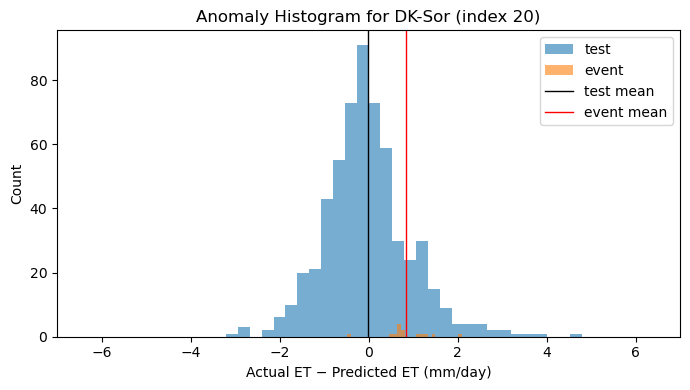

In [138]:
import numpy as np
import matplotlib.pyplot as plt

sites2 = eventdf["SITE_ID"].unique()
site_idx = 20
site_id = sites2[site_idx]
print("Selected site:", site_id)

event_one = dfToList(eventdf, [site_id])[0]
test_one  = dfToList(testdf,  [site_id])[0]

plt.figure(figsize=(7, 4))
plt.hist(test_one, bins=30, alpha=0.6, label="test")
plt.hist(event_one, bins=30, alpha=0.6, label="event")

plt.axvline(np.mean(test_one), color="black" ,linestyle="-", linewidth=1, label="test mean")
plt.axvline(np.mean(event_one), color="red", linestyle="-", linewidth=1, label="event mean")

plt.title(f"Anomaly Histogram for {site_id} (index {site_idx})")
plt.xlabel("Actual ET − Predicted ET (mm/day)")
plt.ylabel("Count")
plt.xlim(-7, 7)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu

eventdf = pd.read_csv("new_runs/RF/run_with_lagged_et01/event.csv")
testdf  = pd.read_csv("new_runs/RF/run_with_lagged_et01/test.csv")

eventdf = eventdf[~eventdf["SITE_ID"].isin(poorPrfSites)]
testdf  = testdf[~testdf["SITE_ID"].isin(poorPrfSites)]

event_anom = eventdf["actual - predicted"].dropna().values
test_anom  = testdf["actual - predicted"].dropna().values

u_stat, p_val = mannwhitneyu(
    event_anom,
    test_anom,
    alternative="two-sided"
)

print("p-value: ", p_val)

p-value:  1.501662602811862e-43


In [ ]:
"